# Business Analytics – E-Commerce-Datenprojekt

**Gruppe 4:** Annika Schöberl, Johanna Huber, Julia Knüttel  
**Thema:** Analyse von Bestell-, Umsatz- und Lieferdaten eines Online-Shops

Dieses Notebook untersucht die im Exposé festgelegte Forschungsfrage und die vier Hypothesen.  
Die Umsetzung verwendet bewusst nur **Python und Pandas**. Die Ergebnisse werden direkt im Jupyter Notebook als übersichtliche Tabellen und einfache textbasierte Balken dargestellt.

## 1. Forschungsfrage und Hypothesen

### Forschungsfrage
**Welche umsatz- und lieferbezogenen Muster lassen sich aus den Bestelldaten des Online-Shops erkennen und welche Erkenntnisse können daraus für die Geschäftsführung abgeleitet werden?**

### Hypothesen

**H1 – Produktkategorien:**  
Einzelne Produktkategorien erzielen einen deutlich höheren Gesamtumsatz als andere.

**H2 – Absatzmärkte:**  
Einige Länder weisen sowohl eine höhere Anzahl an Bestellungen als auch einen höheren Gesamtumsatz auf als andere.

**H3 – Produktkategorien nach Ländern:**  
Die Bedeutung der einzelnen Produktkategorien unterscheidet sich zwischen den Absatzländern.

**H4 – Lieferperformance:**  
Die durchschnittliche Lieferdauer unterscheidet sich zwischen den verschiedenen Absatzländern.

## 2. Verwendete Bibliothek

Für die gesamte Datenanalyse wird nur **Pandas** benötigt.  
Pandas übernimmt das Einlesen, Bereinigen, Gruppieren, Berechnen und tabellarische Darstellen der Daten.

In [ ]:
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## 3. Datensatz einlesen

Die CSV-Datei liegt im gleichen Ordner wie das Notebook.  
Sie verwendet ein Semikolon als Trennzeichen und die Zeichenkodierung `cp1252`.

In [ ]:
df = pd.read_csv(
    "Datengrundlage_Gruppe4.csv",
    sep=";",
    encoding="cp1252"
)

print("Anzahl der Datensätze:", len(df))
print("Anzahl der ursprünglichen Merkmale:", len(df.columns))
df.head()

Anzahl der Datensätze: 100
Anzahl der ursprünglichen Merkmale: 13


,Rechnungsnummer,Kundennummer,Bestellnummer,Produktbezeichnung,Materialnummer,Kategorie,Menge,Einzelpreis_EUR,Bestelldatum,Lieferdatum,Land,Zahlungsart,Bestellstatus
0,RE-2025-50059,K-10285,B-2025-10059,Yoga-Matte Premium,MAT-SPR-002,Sport & Freizeit,1,"32,9",01.02.2025,07.02.2025,Irland,PayPal,Geliefert
1,RE-2026-50005,K-10618,B-2026-10005,Gewürzbox mit 12 Gläsern,MAT-KUE-003,Küche,2,"29,9",01.02.2026,02.02.2026,Belgien,PayPal,Versendet
2,RE-2026-50085,K-10928,B-2026-10085,Notizbuch Hardcover A5,MAT-OFF-001,Büro & Schreibwaren,1,"11,9",01.05.2026,03.05.2026,Italien,Apple Pay,Zugestellt
3,RE-2025-50087,K-10334,B-2025-10087,Küchenwaage digital,MAT-KUE-002,Küche,1,"27,9",01.10.2025,05.10.2025,Frankreich,Klarna,Geliefert
4,RE-2025-50079,K-10236,B-2025-10079,Smart LED Schreibtischlampe,MAT-ELE-003,Elektronik,1,"54,9",01.12.2025,06.12.2025,Italien,Kreditkarte,Geliefert


## 4. Daten vorbereiten

Der Einzelpreis ist in der CSV-Datei mit deutschem Dezimalkomma gespeichert.  
Für Berechnungen wird er deshalb in eine Zahl umgewandelt.

Bestell- und Lieferdatum werden außerdem in Datumswerte umgewandelt.

In [ ]:
df = pd.read_csv(
    "Datengrundlage_Gruppe4.csv",
    sep=";",
    encoding="cp1252",
    decimal=",",
    parse_dates=["Bestelldatum", "Lieferdatum"],
    dayfirst=True
)

# Überprüfung der Datentypen
print(df[["Einzelpreis_EUR", "Bestelldatum", "Lieferdatum"]].dtypes)
df.head()

Einzelpreis_EUR           float64
Bestelldatum       datetime64[ns]
Lieferdatum        datetime64[ns]
dtype: object


,Rechnungsnummer,Kundennummer,Bestellnummer,Produktbezeichnung,Materialnummer,Kategorie,Menge,Einzelpreis_EUR,Bestelldatum,Lieferdatum,Land,Zahlungsart,Bestellstatus
0,RE-2025-50059,K-10285,B-2025-10059,Yoga-Matte Premium,MAT-SPR-002,Sport & Freizeit,1,32.9,2025-02-01,2025-02-07,Irland,PayPal,Geliefert
1,RE-2026-50005,K-10618,B-2026-10005,Gewürzbox mit 12 Gläsern,MAT-KUE-003,Küche,2,29.9,2026-02-01,2026-02-02,Belgien,PayPal,Versendet
2,RE-2026-50085,K-10928,B-2026-10085,Notizbuch Hardcover A5,MAT-OFF-001,Büro & Schreibwaren,1,11.9,2026-05-01,2026-05-03,Italien,Apple Pay,Zugestellt
3,RE-2025-50087,K-10334,B-2025-10087,Küchenwaage digital,MAT-KUE-002,Küche,1,27.9,2025-10-01,2025-10-05,Frankreich,Klarna,Geliefert
4,RE-2025-50079,K-10236,B-2025-10079,Smart LED Schreibtischlampe,MAT-ELE-003,Elektronik,1,54.9,2025-12-01,2025-12-06,Italien,Kreditkarte,Geliefert


## 5. Datenqualität prüfen

Bevor die Daten ausgewertet werden, wird kontrolliert:

- Gibt es fehlende Werte?
- Gibt es vollständig doppelte Zeilen?
- Wie viele Produktkategorien und Länder sind enthalten?
- Welche Bestellstatus kommen vor?

In [ ]:
datenqualitaet = pd.DataFrame({
    "Kennzahl": [
        "Fehlende Werte insgesamt",
        "Doppelte vollständige Zeilen",
        "Produktkategorien",
        "Absatzländer"
    ],
    "Wert": [
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int(df["Kategorie"].nunique()),
        int(df["Land"].nunique())
    ]
})

datenqualitaet

,Kennzahl,Wert
0,Fehlende Werte insgesamt,0
1,Doppelte vollständige Zeilen,0
2,Produktkategorien,8
3,Absatzländer,15


In [ ]:
df["Bestellstatus"].value_counts().rename_axis("Bestellstatus").reset_index(name="Anzahl")

,Bestellstatus,Anzahl
0,Geliefert,60
1,Versendet,21
2,Zugestellt,19


## 6. Neue Kennzahlen berechnen

Für die Forschungsfrage werden zwei zusätzliche Kennzahlen gebildet:

**Umsatz je Datensatz = Menge × Einzelpreis**

**Lieferdauer = Lieferdatum − Bestelldatum**

In [ ]:
df["Umsatz_EUR"] = df["Menge"] * df["Einzelpreis_EUR"]
df["Lieferdauer_Tage"] = (df["Lieferdatum"] - df["Bestelldatum"]).dt.days

df[
    [
        "Bestellnummer",
        "Kategorie",
        "Menge",
        "Einzelpreis_EUR",
        "Umsatz_EUR",
        "Bestelldatum",
        "Lieferdatum",
        "Lieferdauer_Tage"
    ]
].head()

,Bestellnummer,Kategorie,Menge,Einzelpreis_EUR,Umsatz_EUR,Bestelldatum,Lieferdatum,Lieferdauer_Tage
0,B-2025-10059,Sport & Freizeit,1,32.9,32.9,2025-02-01,2025-02-07,6
1,B-2026-10005,Küche,2,29.9,59.8,2026-02-01,2026-02-02,1
2,B-2026-10085,Büro & Schreibwaren,1,11.9,11.9,2026-05-01,2026-05-03,2
3,B-2025-10087,Küche,1,27.9,27.9,2025-10-01,2025-10-05,4
4,B-2025-10079,Elektronik,1,54.9,54.9,2025-12-01,2025-12-06,5


## 7. Überblick für die Geschäftsführung

Zunächst werden einige zentrale Kennzahlen des Datensatzes berechnet.

In [ ]:
management_ueberblick = pd.DataFrame({
    "Kennzahl": [
        "Bestellungen",
        "Verkaufte Einheiten",
        "Gesamtumsatz in EUR",
        "Durchschnittlicher Umsatz je Bestellung in EUR",
        "Durchschnittliche Lieferdauer in Tagen"
    ],
    "Wert": [
        len(df),
        int(df["Menge"].sum()),
        round(df["Umsatz_EUR"].sum(), 2),
        round(df["Umsatz_EUR"].mean(), 2),
        round(df["Lieferdauer_Tage"].mean(), 2)
    ]
})

management_ueberblick

,Kennzahl,Wert
0,Bestellungen,100.00
1,Verkaufte Einheiten,165.00
2,Gesamtumsatz in EUR,4924.81
3,Durchschnittlicher Umsatz je Bestellung in EUR,49.25
4,Durchschnittliche Lieferdauer in Tagen,4.27


In [ ]:
print(
    "Untersuchungszeitraum:",
    df["Bestelldatum"].min().strftime("%d.%m.%Y"),
    "bis",
    df["Bestelldatum"].max().strftime("%d.%m.%Y")
)

Untersuchungszeitraum: 11.01.2025 bis 28.08.2026


# 8. Hypothese H1 – Produktkategorien

**Hypothese:** Einzelne Produktkategorien erzielen einen deutlich höheren Gesamtumsatz als andere.

### Untersuchungsfrage
Welche Produktkategorien tragen am stärksten zum Gesamtumsatz des Online-Shops bei?

Dazu werden Bestellanzahl, verkaufte Menge und Umsatz je Kategorie zusammengefasst. Zusätzlich wird der prozentuale Umsatzanteil berechnet.

In [ ]:
h1 = (
    df.groupby("Kategorie")
    .agg(
        Bestellungen=("Bestellnummer", "count"),
        Verkaufte_Menge=("Menge", "sum"),
        Umsatz_EUR=("Umsatz_EUR", "sum")
    )
    .sort_values("Umsatz_EUR", ascending=False)
)

h1["Umsatzanteil_Prozent"] = (
    h1["Umsatz_EUR"] / df["Umsatz_EUR"].sum() * 100
).round(2)

h1["Umsatz_EUR"] = h1["Umsatz_EUR"].round(2)

h1

,Bestellungen,Verkaufte_Menge,Umsatz_EUR,Umsatzanteil_Prozent
Kategorie,,,,
Elektronik,19,29,1882.10,38.22
Sport & Freizeit,19,37,962.30,19.54
Büro & Schreibwaren,11,21,553.90,11.25
Wohnen,12,18,534.20,10.85
Küche,9,12,304.80,6.19
Lebensmittel,16,23,275.01,5.58
Haushalt,4,11,251.90,5.11
Beauty,10,14,160.60,3.26


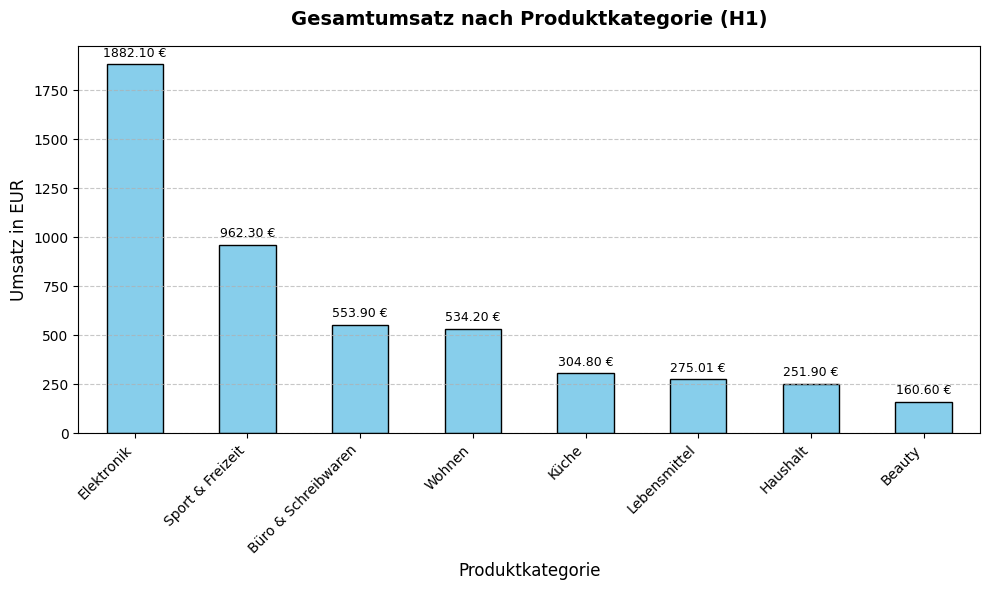

In [ ]:
# Säulendiagramm für den Umsatz nach Produktkategorie (H1)
ax = h1["Umsatz_EUR"].plot(
    kind="bar",
    figsize=(10, 6),
    color="skyblue",
    edgecolor="black"
)

# Diagramm-Details hinzufügen
ax.set_title("Gesamtumsatz nach Produktkategorie (H1)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Produktkategorie", fontsize=12)
ax.set_ylabel("Umsatz in EUR", fontsize=12)
ax.set_xticklabels(h1.index, rotation=45, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.7)

# Werte auf den Säulen anzeigen
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.2f} €",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 8),
        textcoords="offset points",
        fontsize=9
    )

import matplotlib.pyplot as plt
plt.tight_layout()
plt.show()

### Ergebnis zu H1

Die Kategorie **Elektronik** erzielt mit **1.882,10 €** den höchsten Umsatz und trägt rund **38,22 %** zum Gesamtumsatz bei. Danach folgen **Sport & Freizeit** mit **962,30 €** und **Büro & Schreibwaren** mit **553,90 €**.

**Bewertung:** H1 wird durch die vorliegenden Daten gestützt. Die Umsätze sind deutlich ungleich auf die Kategorien verteilt. Für die Geschäftsführung ist besonders relevant, dass Elektronik einen sehr großen Anteil am Gesamtumsatz besitzt.

# 9. Hypothese H2 – Absatzmärkte

**Hypothese:** Einige Länder weisen sowohl eine höhere Anzahl an Bestellungen als auch einen höheren Gesamtumsatz auf als andere.

### Untersuchungsfrage
Welche Absatzmärkte sind hinsichtlich Bestellanzahl und Umsatz besonders relevant?

Hier werden Bestellanzahl, Gesamtumsatz und durchschnittlicher Umsatz je Bestellung pro Land verglichen.

In [ ]:
h2 = (
    df.groupby("Land")
    .agg(
        Bestellungen=("Bestellnummer", "count"),
        Umsatz_EUR=("Umsatz_EUR", "sum"),
        Durchschnittlicher_Bestellwert_EUR=("Umsatz_EUR", "mean")
    )
    .sort_values("Umsatz_EUR", ascending=False)
)

h2["Umsatz_EUR"] = h2["Umsatz_EUR"].round(2)
h2["Durchschnittlicher_Bestellwert_EUR"] = (
    h2["Durchschnittlicher_Bestellwert_EUR"].round(2)
)

h2["Umsatzanteil_Prozent"] = (
    h2["Umsatz_EUR"] / df["Umsatz_EUR"].sum() * 100
).round(2)

h2

,Bestellungen,Umsatz_EUR,Durchschnittlicher_Bestellwert_EUR,Umsatzanteil_Prozent
Land,,,,
Schweiz,7,503.50,71.93,10.22
Frankreich,7,462.98,66.14,9.40
Finnland,6,462.00,77.00,9.38
Deutschland,5,448.60,89.72,9.11
Spanien,5,448.00,89.60,9.10
Österreich,7,432.60,61.80,8.78
Portugal,12,420.79,35.07,8.54
Italien,10,376.80,37.68,7.65
Irland,6,248.20,41.37,5.04


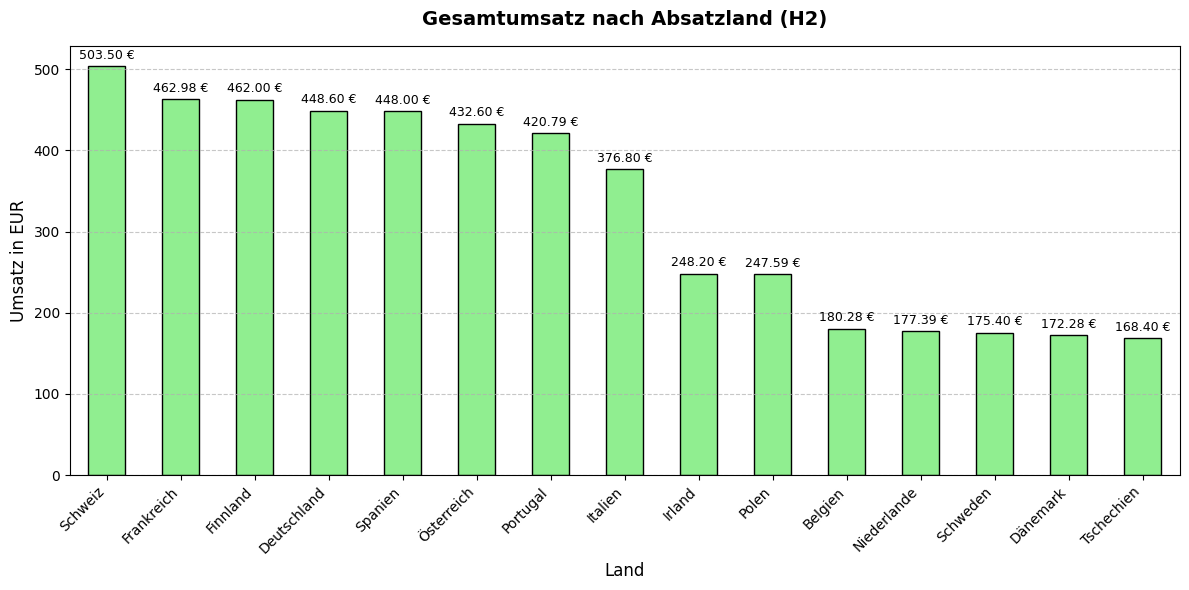

In [ ]:
import matplotlib.pyplot as plt

# Säulendiagramm für den Umsatz nach Land (H2)
ax = h2["Umsatz_EUR"].plot(
    kind="bar",
    figsize=(12, 6),
    color="lightgreen",
    edgecolor="black"
)

# Diagramm-Details hinzufügen
ax.set_title("Gesamtumsatz nach Absatzland (H2)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Land", fontsize=12)
ax.set_ylabel("Umsatz in EUR", fontsize=12)
ax.set_xticklabels(h2.index, rotation=45, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.7)

# Werte auf den Säulen anzeigen
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.2f} €",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 8),
        textcoords="offset points",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [ ]:
land_meiste_bestellungen = h2["Bestellungen"].idxmax()
land_hoechster_umsatz = h2["Umsatz_EUR"].idxmax()

print(
    "Land mit den meisten Bestellungen:",
    land_meiste_bestellungen,
    "-",
    int(h2.loc[land_meiste_bestellungen, "Bestellungen"]),
    "Bestellungen"
)

print(
    "Land mit dem höchsten Umsatz:",
    land_hoechster_umsatz,
    "-",
    round(h2.loc[land_hoechster_umsatz, "Umsatz_EUR"], 2),
    "EUR"
)

Land mit den meisten Bestellungen: Portugal - 12 Bestellungen
Land mit dem höchsten Umsatz: Schweiz - 503.5 EUR


### Ergebnis zu H2

Den höchsten Gesamtumsatz erzielt die **Schweiz mit 503,50 €**. Die meisten Bestellungen stammen dagegen aus **Portugal mit 12 Bestellungen**.

Damit liegen Bestellhäufigkeit und Umsatz nicht automatisch im gleichen Land am höchsten.

**Bewertung:** H2 wird **teilweise gestützt**. Es gibt deutliche Unterschiede zwischen den Absatzmärkten, allerdings ist ein Land mit besonders vielen Bestellungen nicht zwingend gleichzeitig das Land mit dem höchsten Umsatz. Für die Geschäftsführung zeigt dies, dass neben der Bestellanzahl auch der Wert der Bestellungen berücksichtigt werden sollte.

# 10. Hypothese H3 – Produktkategorien nach Ländern

**Hypothese:** Die Bedeutung der einzelnen Produktkategorien unterscheidet sich zwischen den Absatzländern.

### Untersuchungsfrage
Gibt es Produktkategorien, die in bestimmten Ländern einen besonders hohen Umsatz erzielen?

Dazu werden Land und Produktkategorie miteinander kombiniert.

In [ ]:
h3 = (
    df.groupby(["Land", "Kategorie"])["Umsatz_EUR"]
    .sum()
    .unstack(fill_value=0)
    .round(2)
)

h3

Kategorie,Beauty,Büro & Schreibwaren,Elektronik,Haushalt,Küche,Lebensmittel,Sport & Freizeit,Wohnen
Land,,,,,,,,
Belgien,0.0,0.0,0.0,0.0,87.7,32.88,59.7,0.0
Deutschland,0.0,171.6,109.8,91.6,0.0,25.80,49.8,0.0
Dänemark,0.0,0.0,0.0,0.0,0.0,10.98,144.4,16.9
Finnland,8.9,0.0,269.7,0.0,18.9,0.00,164.5,0.0
Frankreich,44.7,0.0,379.4,0.0,27.9,10.98,0.0,0.0
Irland,8.9,0.0,34.9,0.0,29.9,21.90,32.9,119.7
Italien,0.0,64.7,214.6,0.0,18.9,38.70,0.0,39.9
Niederlande,29.8,35.7,0.0,0.0,0.0,78.99,32.9,0.0
Polen,41.6,0.0,134.7,0.0,0.0,5.49,65.8,0.0


Die Tabelle zeigt für jedes Land, wie viel Umsatz mit den einzelnen Produktkategorien erzielt wurde.  
Zur leichteren Interpretation wird zusätzlich je Land die umsatzstärkste Kategorie ermittelt.

In [ ]:
h3_top = (
    df.groupby(["Land", "Kategorie"])["Umsatz_EUR"]
    .sum()
    .reset_index()
    .sort_values(["Land", "Umsatz_EUR"], ascending=[True, False])
    .groupby("Land")
    .head(1)
    .sort_values("Land")
)

h3_top["Umsatz_EUR"] = h3_top["Umsatz_EUR"].round(2)
h3_top.reset_index(drop=True)

,Land,Kategorie,Umsatz_EUR
0,Belgien,Küche,87.70
1,Deutschland,Büro & Schreibwaren,171.60
2,Dänemark,Sport & Freizeit,144.40
3,Finnland,Elektronik,269.70
4,Frankreich,Elektronik,379.40
5,Irland,Wohnen,119.70
6,Italien,Elektronik,214.60
7,Niederlande,Lebensmittel,78.99
8,Polen,Elektronik,134.70
9,Portugal,Elektronik,94.80


### Ergebnis zu H3

Die umsatzstärkste Produktkategorie ist nicht in jedem Land identisch. In mehreren Ländern ist **Elektronik** besonders umsatzstark, während beispielsweise in Belgien **Küche**, in Dänemark und Schweden **Sport & Freizeit**, in Irland und Tschechien **Wohnen** und in den Niederlanden **Lebensmittel** an erster Stelle stehen.

**Bewertung:** H3 wird durch die Daten gestützt. Die Umsatzbedeutung der Kategorien unterscheidet sich zwischen den Ländern. Für die Geschäftsführung kann dies ein Hinweis darauf sein, Sortimente und Marketingmaßnahmen je Absatzmarkt unterschiedlich zu betrachten.

# 11. Hypothese H4 – Lieferperformance

**Hypothese:** Die durchschnittliche Lieferdauer unterscheidet sich zwischen den verschiedenen Absatzländern.

### Untersuchungsfrage
Welche Länder weisen vergleichsweise kurze oder lange Lieferzeiten auf?

Hier wird die durchschnittliche, minimale und maximale Lieferdauer je Land berechnet.

In [ ]:
h4 = (
    df.groupby("Land")
    .agg(
        Bestellungen=("Bestellnummer", "count"),
        Durchschnittliche_Lieferdauer_Tage=("Lieferdauer_Tage", "mean"),
        Min_Lieferdauer_Tage=("Lieferdauer_Tage", "min"),
        Max_Lieferdauer_Tage=("Lieferdauer_Tage", "max")
    )
    .sort_values("Durchschnittliche_Lieferdauer_Tage")
)

h4["Durchschnittliche_Lieferdauer_Tage"] = (
    h4["Durchschnittliche_Lieferdauer_Tage"].round(2)
)

h4

,Bestellungen,Durchschnittliche_Lieferdauer_Tage,Min_Lieferdauer_Tage,Max_Lieferdauer_Tage
Land,,,,
Finnland,6,2.83,1,4
Tschechien,5,3.00,1,7
Belgien,6,3.17,1,7
Irland,6,4.00,1,7
Portugal,12,4.17,1,7
Österreich,7,4.29,3,6
Polen,7,4.29,2,6
Frankreich,7,4.29,2,7
Spanien,5,4.40,1,7


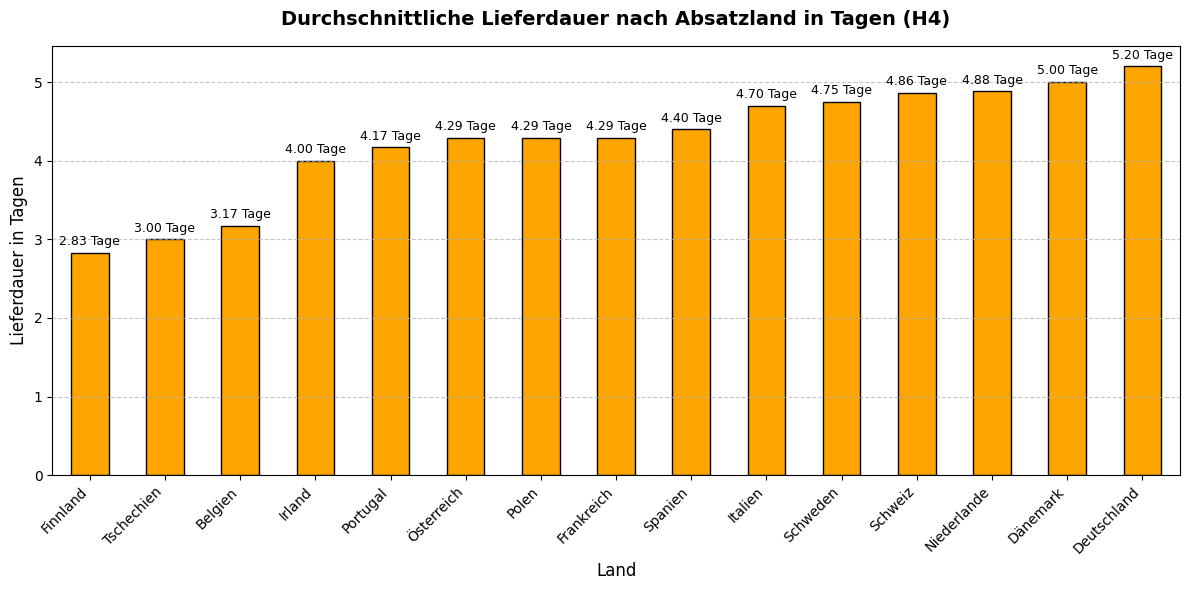

In [ ]:
import matplotlib.pyplot as plt

# Säulendiagramm für die durchschnittliche Lieferdauer nach Land (H4)
ax = h4["Durchschnittliche_Lieferdauer_Tage"].plot(
    kind="bar",
    figsize=(12, 6),
    color="orange",
    edgecolor="black"
)

# Diagramm-Details hinzufügen
ax.set_title("Durchschnittliche Lieferdauer nach Absatzland in Tagen (H4)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Land", fontsize=12)
ax.set_ylabel("Lieferdauer in Tagen", fontsize=12)
ax.set_xticklabels(h4.index, rotation=45, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.7)

# Werte auf den Säulen anzeigen
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.2f} Tage",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 8),
        textcoords="offset points",
        fontsize=9
    )

plt.tight_layout()
plt.show()

### Ergebnis zu H4

Die durchschnittliche Lieferdauer unterscheidet sich zwischen den Ländern.  
**Finnland** weist mit durchschnittlich **2,83 Tagen** die kürzeste Lieferdauer auf.  
**Deutschland** weist mit durchschnittlich **5,20 Tagen** die längste Lieferdauer im Datensatz auf.

**Bewertung:** H4 wird durch die vorliegenden Daten gestützt. Für die Geschäftsführung sind insbesondere Länder mit höheren durchschnittlichen Lieferzeiten interessant, da dort mögliche Ansatzpunkte für eine genauere Analyse der Auftragsabwicklung bestehen.

# 12. Gesamtergebnis für die Geschäftsführung

Die vier Untersuchungen zeigen mehrere betriebswirtschaftlich relevante Muster:

1. **Sortiment:** Elektronik ist mit Abstand die umsatzstärkste Produktkategorie.
2. **Märkte:** Länder unterscheiden sich deutlich hinsichtlich Umsatz und Bestellanzahl.
3. **Länderspezifisches Sortiment:** Die umsatzstärksten Kategorien sind nicht in allen Ländern identisch.
4. **Lieferperformance:** Auch die durchschnittliche Lieferdauer unterscheidet sich zwischen den Absatzländern.

Damit liefert die Analyse einen kompakten Überblick darüber, **was**, **wo** und **mit welcher Liefergeschwindigkeit** verkauft wird.

In [ ]:
ergebnisuebersicht = pd.DataFrame({
    "Hypothese": ["H1", "H2", "H3", "H4"],
    "Thema": [
        "Umsatz nach Produktkategorie",
        "Umsatz und Bestellungen nach Land",
        "Produktkategorien nach Land",
        "Lieferdauer nach Land"
    ],
    "Ergebnis": [
        "gestützt",
        "teilweise gestützt",
        "gestützt",
        "gestützt"
    ],
    "Zentrale Erkenntnis": [
        "Elektronik ist die umsatzstärkste Kategorie.",
        "Schweiz hat den höchsten Umsatz, Portugal die meisten Bestellungen.",
        "Die stärkste Kategorie unterscheidet sich zwischen mehreren Ländern.",
        "Finnland hat die kürzeste und Deutschland die längste mittlere Lieferdauer."
    ]
})

ergebnisuebersicht

,Hypothese,Thema,Ergebnis,Zentrale Erkenntnis
0,H1,Umsatz nach Produktkategorie,gestützt,Elektronik ist die umsatzstärkste Kategorie.
1,H2,Umsatz und Bestellungen nach Land,teilweise gestützt,"Schweiz hat den höchsten Umsatz, Portugal die ..."
2,H3,Produktkategorien nach Land,gestützt,Die stärkste Kategorie unterscheidet sich zwis...
3,H4,Lieferdauer nach Land,gestützt,Finnland hat die kürzeste und Deutschland die ...


# 13. Grenzen der Analyse

Die Ergebnisse gelten ausschließlich für den vorliegenden Datensatz mit 100 Bestellungen.  
Aus den Daten können Muster und Unterschiede beschrieben werden, jedoch keine allgemeingültigen Aussagen über den gesamten E-Commerce-Markt abgeleitet werden.

Außerdem zeigt ein Zusammenhang in den Daten nicht automatisch eine Ursache. Beispielsweise lässt sich aus einer längeren durchschnittlichen Lieferzeit eines Landes nicht direkt ableiten, warum diese entsteht.

Für eine reale Unternehmensentscheidung wären größere Datenmengen und zusätzliche Informationen, beispielsweise Versanddienstleister, Versandkosten oder Retouren, sinnvoll.

# 14. Technische Umsetzung und GitHub

Das Projekt besteht aus:

- `E-Commerce_Datenanalyse_Gruppe4.ipynb` – vollständige Analyse
- `Datengrundlage_Gruppe4.csv` – verwendete Datengrundlage
- `README.md` – Projektbeschreibung für GitHub
- `KI_Nutzung.md` – Dokumentation der KI-Unterstützung
- `Praesentationsleitfaden.md` – Vorbereitung für die Ergebnispräsentation
- `Expose_E-Commerce.pdf` – zugrunde liegendes Exposé

Die Versionsverwaltung und gemeinsame Ablage erfolgen über **GitHub**.

# 15. Fazit

Die Forschungsfrage konnte anhand der vier Hypothesen systematisch untersucht werden.  
Mit grundlegenden Funktionen von Python und Pandas konnten aus den Rohdaten zusätzliche Kennzahlen gebildet, Gruppen miteinander verglichen und betriebswirtschaftlich relevante Erkenntnisse abgeleitet werden.

Die Analyse zeigt insbesondere die hohe Umsatzbedeutung der Kategorie Elektronik, Unterschiede zwischen den Absatzmärkten sowie Unterschiede in der Lieferperformance. Damit werden die Bestelldaten in eine Form überführt, die für eine Geschäftsführung wesentlich leichter interpretierbar ist.